# 📘 AUDITORÍA DE IDENTIFICABILIDAD FRACCIONARIA EN OSCILADORES ACOPLADOS
## Fase Experimental: Fantoma Físico Acústico y Espectroscopía de Admitancia del Puente

### Sección 0: Configuración del Entorno y Carga Íntegra de Datos
**Objetivo:** Preparar el entorno computacional, cargar las señales acústicas sin compresión y cuantificar el piso de ruido ambiental pre-ataque (Regla **R-N4**).

**Marco Metodológico (Reencuadre Aprobado):**
En un oscilador viscoelástico acoplado a una frontera radiativa (cuerda de guitarra sobre puente y tapa armónica), la disipación intrínseca gobernada por la derivada fraccionaria de Caputo (${}^C D_t^\alpha$) compite con canales disipativos extrínsecos. Este cuaderno implementa el pipeline de auditoría para demostrar analítica y experimentalmente las dos paredes de identificabilidad:
1. **Pared Temporal (Dominio del Tiempo):** El tiempo de cruce $t^*$ donde la cola asintótica de Mittag-Leffler ($t^{-\alpha}$) supera al modo resonante exponencial ($e^{-\sigma t}$) ocurre órdenes de magnitud por debajo del piso de ruido instrumental.
2. **Pared Espectral (Dominio de la Frecuencia):** Las tasas de decaimiento modal $\sigma_n$ están dominadas por la parte real de la admitancia mecánica del puente, $\sigma_n \approx (T/L)\,\text{Re}[Y(\omega_n)]$, permitiendo utilizar la cuerda como espectrómetro pasivo de la estructura.

---
### Protocolo Experimental ($f_0 \approx 196\text{ Hz}$, Cuerda Sol / G3, $T/L = 107.7\text{ kg/s}^2$)

| Archivo | Excitación | Captación | Propósito Físico |
| :--- | :--- | :--- | :--- |
| `guitarra cuerda sol dedo  linea.wav` | Dedo (suave) | Piezoeléctrico | Menor excitación de modos altos, transducción directa en puente |
| `guitarra cuerda sol dedo mic.wav` | Dedo (suave) | Micrófono | Radiación acústica acoplada cuerda-tapa-aire |
| `guitarra cuerda sol pua linea.wav` | Púa (rígida) | Piezoeléctrico | Excitación rica en armónicos superiores, ataque impulsivo |
| `guitarra cuerda sol pua miic.wav` | Púa (rígida) | Micrófono | Respuesta radiativa completa con transitorios de alta frecuencia |

---
### Reglas de Auditoría Activas en este Pipeline
* **R-N1 (Robustez ante batido modal):** Uso exclusivo de **mediana e IQR** en estimadores sujetos al batido de polarización ($\sim 8\text{ Hz}$).
* **R-N2 (Métrica de comparación de modelos):** Prohibido reportar $\Delta\text{AIC}$ crudo con $n \sim 10^4$ muestras autocorrelacionadas; se reporta la razón $\text{RSS}_{\text{POT}}/\text{RSS}_{\text{EXP}}$ y $\Delta\text{AIC}/n = \ln(\text{RSS}_{\text{POT}}/\text{RSS}_{\text{EXP}})$.
* **R-N3 (Transparencia de segmentación):** Impresión obligatoria de tiempos de inicio y duraciones efectivas de cada segmento.
* **R-N4 (SNR Verdadero):** Relación señal-ruido medida respecto al piso de ruido ambiental **pre-ataque**, nunca respecto al mínimo interno del segmento truncado.

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import scipy
from scipy import signal
from scipy.optimize import curve_fit
import librosa
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# Configuración gráfica estilo publicación (APS / Nature)
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'legend.fontsize': 10,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'axes.grid': True,
    'grid.alpha': 0.3
})

print('✅ Entorno configurado correctamente.')
print(f' - NumPy v{np.__version__}')
print(f' - SciPy v{scipy.__version__}')
print(f' - Librosa v{librosa.__version__}\n')

# Carga de archivos en Google Colab o directorio local
archivos_esperados = [
    'guitarra cuerda sol dedo  linea.wav',
    'guitarra cuerda sol dedo mic.wav',
    'guitarra cuerda sol pua linea.wav',
    'guitarra cuerda sol pua miic.wav'
]

archivos_presentes = [f for f in archivos_esperados if os.path.exists(f)]
if len(archivos_presentes) < 4:
    try:
        from google.colab import files
        print('📂 Por favor, selecciona los 4 archivos .wav:')
        uploaded = files.upload()
        archivos_cargados = list(uploaded.keys())
    except ImportError:
        archivos_cargados = [f for f in os.listdir('.') if f.endswith('.wav')]
else:
    archivos_cargados = archivos_presentes

datos_crudos = {}
print('\n🔄 Verificando integridad de archivos y piso de ruido pre-ataque (R-N4)...')
for nombre in sorted(archivos_cargados):
    y, sr = librosa.load(nombre, sr=None, mono=True)
    # Piso de ruido pre-ataque: primeros 500 ms antes del primer toque (que ocurre ~1.1 s)
    n_pre = int(0.5 * sr)
    ruido_pre_rms = np.sqrt(np.mean(y[:n_pre]**2)) + 1e-12
    datos_crudos[nombre] = {
        'senal': y,
        'sr': sr,
        'ruido_pre_rms': ruido_pre_rms
    }
    print(f' ✅ {nombre}')
    print(f'    - Tasa de muestreo: {sr} Hz | Duración: {len(y)/sr:.2f} s | Muestras: {len(y)}')
    print(f'    - Rango dinámico: [{np.min(y):.3f}, {np.max(y):.3f}] | Piso RMS pre-ataque: {ruido_pre_rms:.2e}')

✅ Entorno configurado correctamente.
 - NumPy v2.4.6
 - SciPy v1.16.3
 - Librosa v0.11.0


🔄 Verificando integridad de archivos y piso de ruido pre-ataque (R-N4)...
 ✅ guitarra cuerda sol dedo  linea.wav
    - Tasa de muestreo: 44100 Hz | Duración: 33.19 s | Muestras: 1463608
    - Rango dinámico: [-0.513, 0.664] | Piso RMS pre-ataque: 1.77e-04
 ✅ guitarra cuerda sol dedo mic.wav
    - Tasa de muestreo: 44100 Hz | Duración: 33.19 s | Muestras: 1463608
    - Rango dinámico: [-0.490, 0.667] | Piso RMS pre-ataque: 3.16e-03
 ✅ guitarra cuerda sol pua linea.wav
    - Tasa de muestreo: 44100 Hz | Duración: 33.19 s | Muestras: 1463608
    - Rango dinámico: [-0.207, 0.262] | Piso RMS pre-ataque: 2.45e-04
 ✅ guitarra cuerda sol pua miic.wav
    - Tasa de muestreo: 44100 Hz | Duración: 33.19 s | Muestras: 1463608
    - Rango dinámico: [-0.284, 0.407] | Piso RMS pre-ataque: 2.00e-03


---
# 📡 Sección 1: Filtrado Paso Banda (SOS) y Segmentación de Eventos Independientes

### 1.1 Aislamiento del Modo Fundamental ($f_0 = 196\text{ Hz}$)
La Transformada de Hilbert requiere una señal cuasi-monocromática que satisfaga la condición de separabilidad espectral de **Bedrosian** ($\eta = f_0 / B \gg 1$). Aplicamos un filtro Butterworth pasabanda de 2.º orden implementado en secciones de segundo orden (`SOS`) con filtrado bidireccional de fase cero (`sosfiltfilt`), garantizando:
1. Ganancia unitaria y fase nula en $f_0 = 196\text{ Hz}$.
2. Rechazo superior a $80\text{ dB}$ sobre el segundo armónico ($2f_0 = 392\text{ Hz}$).

### 1.2 Segmentación por Prominencia Física y Corte Dinámico (Reglas R-N3 y R-N4)
Dado que el operador de Caputo ${}^C D_{0+}^\alpha f(t)$ posee un núcleo con memoria desde $t=0$, cada pulsación (*pluck*) constituye un Problema de Valor Inicial independiente. Se aíslan los 5 ataques físicos mediante ordenamiento de prominencia RMS y se determina la ventana útil antes de que la envolvente alcance el piso de ruido pre-ataque.

In [ ]:
def disenar_filtro_sos(f_central, bw, fs, orden=2):
    nyq = 0.5 * fs
    low = max((f_central - bw / 2.0) / nyq, 0.001)
    high = min((f_central + bw / 2.0) / nyq, 0.999)
    sos = signal.butter(orden, [low, high], btype='bandpass', output='sos')
    return sos

F0_SOL = 196.0
BW_FUND = 20.0  # Corte efectivo [186 Hz, 206 Hz]

resultados_filtrado = {}
print('🚀 Ejecutando filtrado pasabanda del modo fundamental (f0 = 196 Hz)...\n')

for nombre, info in datos_crudos.items():
    y = info['senal']
    sr = info['sr']
    sos = disenar_filtro_sos(F0_SOL, BW_FUND, sr, orden=2)
    y_filt = signal.sosfiltfilt(sos, y)

    # Cálculo de rechazo de 2f0 en el espectro filtrado
    freqs = np.fft.rfftfreq(len(y_filt), d=1.0/sr)
    mag = np.abs(np.fft.rfft(y_filt))
    idx_f0 = np.argmin(np.abs(freqs - F0_SOL))
    idx_2f0 = np.argmin(np.abs(freqs - 2*F0_SOL))
    relacion_db = 20 * np.log10((mag[idx_f0] + 1e-12) / (mag[idx_2f0] + 1e-12))

    # Ruido pre-ataque en la banda filtrada (R-N4)
    ruido_banda_rms = np.sqrt(np.mean(y_filt[:int(0.5*sr)]**2)) + 1e-12

    resultados_filtrado[nombre] = {
        'original': y,
        'filtrada': y_filt,
        'sr': sr,
        'ruido_banda_rms': ruido_banda_rms,
        'rechazo_2f0_db': relacion_db
    }
    print(f'📁 {nombre}')
    print(f'   - Banda de paso: [{F0_SOL - BW_FUND/2:.1f} Hz, {F0_SOL + BW_FUND/2:.1f} Hz]')
    print(f'   - Relación f0/2f0: {relacion_db:.1f} dB (✅ Armónico 2f0 suprimido)\n')

🚀 Ejecutando filtrado pasabanda del modo fundamental (f0 = 196 Hz)...

📁 guitarra cuerda sol dedo  linea.wav
   - Banda de paso: [186.0 Hz, 206.0 Hz]
   - Relación f0/2f0: 77.5 dB (✅ Armónico 2f0 suprimido)

📁 guitarra cuerda sol dedo mic.wav
   - Banda de paso: [186.0 Hz, 206.0 Hz]
   - Relación f0/2f0: 97.1 dB (✅ Armónico 2f0 suprimido)

📁 guitarra cuerda sol pua linea.wav
   - Banda de paso: [186.0 Hz, 206.0 Hz]
   - Relación f0/2f0: 73.9 dB (✅ Armónico 2f0 suprimido)

📁 guitarra cuerda sol pua miic.wav
   - Banda de paso: [186.0 Hz, 206.0 Hz]
   - Relación f0/2f0: 85.5 dB (✅ Armónico 2f0 suprimido)



In [ ]:
def segmentar_decaimientos(y_filt, sr, ruido_rms, n_esperados=5):
    # Envolvente RMS suave en ventanas de 20 ms para detectar ataques
    win_samples = int(0.02 * sr)
    rms_env = np.sqrt(np.convolve(y_filt**2, np.ones(win_samples)/win_samples, mode='same'))

    dist_min = int(3.5 * sr)  # Separación mínima de 3.5 s entre toques
    picos, props = signal.find_peaks(rms_env, distance=dist_min, prominence=np.max(rms_env)*0.02)

    # Selección de los Top-5 picos por prominencia física
    if len(picos) > n_esperados:
        idx_top = np.argsort(props['prominences'])[::-1][:n_esperados]
        picos = np.sort(picos[idx_top])

    segmentos = []
    offset_ataque = int(0.05 * sr)  # Descartar primeros 50 ms de transitorio de púa/dedo

    for i, pk in enumerate(picos):
        inicio = pk + offset_ataque
        limite_max = picos[i+1] - int(0.2 * sr) if i < len(picos) - 1 else len(y_filt) - 1
        limite_max = min(limite_max, inicio + int(2.5 * sr))

        env_sub = rms_env[inicio:limite_max]
        pico_val = rms_env[pk]
        # Umbral dinámico: donde la señal cae a 3x el piso de ruido de banda o al 1.5% del pico
        umbral = max(3.0 * ruido_rms, 0.015 * pico_val)
        debajo = np.where(env_sub < umbral)[0]

        if len(debajo) > 0:
            fin = inicio + max(debajo[0], int(0.80 * sr))
        else:
            fin = inicio + int(0.85 * sr)

        seg = y_filt[inicio:fin]
        snr_true_db = 20 * np.log10((pico_val + 1e-12) / (ruido_rms + 1e-12))
        segmentos.append({
            'id': i,
            't_inicio': inicio / sr,
            'duracion': (fin - inicio) / sr,
            'senal': seg,
            'snr_true_db': snr_true_db
        })
    return segmentos

segmentos_por_archivo = {}
print('✂️ SEGMENTACIÓN DE EVENTOS Y AUDITORÍA DE DURACIÓN / SNR VERDADERO (R-N3, R-N4)')
print('='*82)
for nombre, info in resultados_filtrado.items():
    segs = segmentar_decaimientos(info['filtrada'], info['sr'], info['ruido_banda_rms'])
    segmentos_por_archivo[nombre] = segs
    print(f'\n📁 ARCHIVO: {nombre} ({len(segs)} decaimientos aislados)')
    for s in segs:
        print(f"   Segmento {s['id']}: Inicio = {s['t_inicio']:5.2f} s | Duración = {s['duracion']:.2f} s | SNR_true = {s['snr_true_db']:.1f} dB")

✂️ SEGMENTACIÓN DE EVENTOS Y AUDITORÍA DE DURACIÓN / SNR VERDADERO (R-N3, R-N4)

📁 ARCHIVO: guitarra cuerda sol dedo  linea.wav (5 decaimientos aislados)
   Segmento 0: Inicio =  1.17 s | Duración = 0.80 s | SNR_true = 62.5 dB
   Segmento 1: Inicio =  7.61 s | Duración = 0.81 s | SNR_true = 63.0 dB
   Segmento 2: Inicio = 13.19 s | Duración = 0.81 s | SNR_true = 59.5 dB
   Segmento 3: Inicio = 18.86 s | Duración = 0.90 s | SNR_true = 59.1 dB
   Segmento 4: Inicio = 24.51 s | Duración = 0.90 s | SNR_true = 59.1 dB

📁 ARCHIVO: guitarra cuerda sol dedo mic.wav (5 decaimientos aislados)
   Segmento 0: Inicio =  1.19 s | Duración = 0.80 s | SNR_true = 75.1 dB
   Segmento 1: Inicio =  7.63 s | Duración = 0.80 s | SNR_true = 75.8 dB
   Segmento 2: Inicio = 13.21 s | Duración = 0.80 s | SNR_true = 72.1 dB
   Segmento 3: Inicio = 18.88 s | Duración = 0.80 s | SNR_true = 71.8 dB
   Segmento 4: Inicio = 24.53 s | Duración = 0.80 s | SNR_true = 71.9 dB

📁 ARCHIVO: guitarra cuerda sol pua linea.wav

---
# 📐 Sección 2: Transformada de Hilbert y Auditoría Rigurosa del Teorema de Bedrosian

Para una señal real $x(t) = A(t)\cos(\omega_0 t + \phi_0)$, la señal analítica de Gabor es $z(t) = x(t) + i\mathcal{H}\{x(t)\}$, cuya magnitud recupera la envolvente instantánea $A(t) = |z(t)|$ **si y solo si** los soportes espectrales de la envolvente y la portadora son disjuntos (**Teorema de Bedrosian, 1963**):
$$\text{supp}\left(\mathcal{F}\{A(t)\}\right) \subset [-B, B], \qquad \eta = \frac{f_0}{B} \gg 1.$$

**Corrección de Punto Ciego:** Además del ancho de banda de relajación $B_\tau = 1/\tau$, medimos directamente el ancho de banda espectral al $99\%$ de energía de la envolvente centrada ($B_{99}$), el cual incluye la modulación por batido de polarización ($\Delta f \approx 8\text{ Hz}$).

In [ ]:
envolventes_por_archivo = {}
print('🔬 APLICANDO TRANSFORMADA DE HILBERT Y AUDITORÍA DE BEDROSIAN')
print('='*82)

for nombre, segs in segmentos_por_archivo.items():
    sr = resultados_filtrado[nombre]['sr']
    env_lista = []
    print(f'\n🎼 Procesando: {nombre}')
    for s in segs:
        seg = s['senal']
        t = np.arange(len(seg)) / sr + 1.0 / sr  # t > 0 para evitar singularidad en log(t)
        z = signal.hilbert(seg)
        env = np.abs(z)

        # Recorte de 30 ms en extremos para suprimir efecto de borde de Hilbert
        n_cut = int(0.03 * sr)
        t_clean = t[n_cut:-n_cut]
        env_clean = env[n_cut:-n_cut]

        # Estimación de tau y ancho de banda B_tau = 1 / tau
        pendiente_exp, log_a0 = np.polyfit(t_clean, np.log(env_clean + 1e-12), 1)
        sigma_est = -pendiente_exp
        tau_est = 1.0 / max(sigma_est, 0.1)
        B_tau = 1.0 / tau_est
        eta_tau = F0_SOL / B_tau

        # Ancho de banda espectral real al 95% de la energía dinámica de la envolvente (incluyendo batido)
        env_zero = env_clean - np.mean(env_clean)
        f_env = np.fft.rfftfreq(len(env_zero), d=1.0/sr)
        psd_env = np.abs(np.fft.rfft(env_zero))**2
        cum_energy = np.cumsum(psd_env) / (np.sum(psd_env) + 1e-12)
        B_eff = max(f_env[np.searchsorted(cum_energy, 0.95)], B_tau)
        eta_eff = F0_SOL / B_eff

        env_lista.append({
            'id': s['id'],
            't': t_clean,
            'env': env_clean,
            'sigma_ols': sigma_est,
            'tau': tau_est,
            'B_tau': B_tau,
            'eta_tau': eta_tau,
            'eta_eff': eta_eff,
            'snr_true_db': s['snr_true_db']
        })
        print(f"   segmento_{s['id']}: τ = {tau_est:.2f} s | B_τ = {B_tau:.2f} Hz (η_τ = {eta_tau:.1f}) | η_efectivo (con batido) = {eta_eff:.1f} ✅")
    envolventes_por_archivo[nombre] = env_lista

🔬 APLICANDO TRANSFORMADA DE HILBERT Y AUDITORÍA DE BEDROSIAN

🎼 Procesando: guitarra cuerda sol dedo  linea.wav
   segmento_0: τ = 0.20 s | B_τ = 5.06 Hz (η_τ = 38.8) | η_efectivo (con batido) = 9.1 ✅
   segmento_1: τ = 0.25 s | B_τ = 4.02 Hz (η_τ = 48.7) | η_efectivo (con batido) = 8.2 ✅
   segmento_2: τ = 0.25 s | B_τ = 4.07 Hz (η_τ = 48.1) | η_efectivo (con batido) = 8.7 ✅
   segmento_3: τ = 0.27 s | B_τ = 3.74 Hz (η_τ = 52.4) | η_efectivo (con batido) = 9.1 ✅
   segmento_4: τ = 0.26 s | B_τ = 3.79 Hz (η_τ = 51.7) | η_efectivo (con batido) = 9.1 ✅

🎼 Procesando: guitarra cuerda sol dedo mic.wav
   segmento_0: τ = 0.14 s | B_τ = 7.17 Hz (η_τ = 27.4) | η_efectivo (con batido) = 9.1 ✅
   segmento_1: τ = 0.16 s | B_τ = 6.39 Hz (η_τ = 30.7) | η_efectivo (con batido) = 9.1 ✅
   segmento_2: τ = 0.13 s | B_τ = 7.68 Hz (η_τ = 25.5) | η_efectivo (con batido) = 9.7 ✅
   segmento_3: τ = 0.13 s | B_τ = 7.79 Hz (η_τ = 25.2) | η_efectivo (con batido) = 9.7 ✅
   segmento_4: τ = 0.13 s | B_τ = 7.71 

---
# 🧱 Sección 3: Pared de Identificabilidad Temporal (Cruce $t^*$, Regla R-N2 y Embudo de $\beta_{\text{eff}}$)

### 3.1 Demostración Analítico-Numérica del Tiempo de Cruce $t^*$
De la descomposición del contorno de Bromwich deformado (Cap. 2 y Cap. 3), la envolvente de relajación del modo fundamental obedece el ansatz de dos escalas:
$$A(t) \approx A_0 e^{-\sigma t} + B_\alpha t^{-\alpha}, \qquad \text{con} \quad \frac{B_\alpha}{A_0} \approx \frac{\gamma}{\omega_0^2 \Gamma(1-\alpha)} = \frac{2\sigma \,\omega_0^{-(1+\alpha)}}{\sin(\pi\alpha/2)\,\Gamma(1-\alpha)}.$$
Antes de ajustar datos, calculamos el tiempo de cruce $t^*$ en el cual ambos términos se igualan ($A_0 e^{-\sigma t^*} = B_\alpha (t^*)^{-\alpha}$) y la razón cola/polo en $t = 0.8\text{ s}$.

In [ ]:
from scipy.special import gamma as gamma_func
from scipy.optimize import brentq

omega_0 = 2 * np.pi * F0_SOL
sigma_tipico = 5.5  # s^-1 promedio experimental en G3

print('📐 AUDITORÍA TEÓRICA PRE-AJUSTE: RAZÓN COLA/POLO Y TIEMPO DE CRUCE t*')
print('='*78)
print(f'Parámetros físicos G3: f0 = {F0_SOL} Hz (ω0 = {omega_0:.1f} rad/s), σ ≈ {sigma_tipico} s⁻¹\n')
print(f"{'Orden α':^10} | {'Cociente B_α / A_0':^20} | {'Cola/Polo en t=0.8s':^22} | {'Cruce teórico t* (s)':^20}")
print('-'*78)

for alpha_val in [0.2, 0.4, 0.5, 0.6, 0.8]:
    r_bound = (2.0 * sigma_tipico * (omega_0**(-(1.0 + alpha_val)))) / (
        np.sin(np.pi * alpha_val / 2.0) * gamma_func(1.0 - alpha_val)
    )
    razon_08 = (r_bound * (0.8**(-alpha_val))) / np.exp(-sigma_tipico * 0.8)
    # Resolver exp(-sigma * t*) = r_bound * (t*)^(-alpha)
    f_cruce = lambda t_val: -sigma_tipico * t_val - np.log(r_bound) + alpha_val * np.log(t_val)
    t_star = brentq(f_cruce, 0.5, 50.0)
    atenuacion_db = 20 * np.log10(np.exp(-sigma_tipico * t_star))
    print(f'{alpha_val:^10.1f} | {r_bound:^20.2e} | {razon_08:^22.2e} | {t_star:6.2f} s ({atenuacion_db:.0f} dB) ')

print('\n📌 CONCLUSIÓN ANALÍTICA: En t = 0.8 s, la cola de Mittag-Leffler está ~6 a 8 órdenes de magnitud')
print('   por debajo del polo exponencial. Para alcanzar t* (~3.2 a 4.1 s) se requeriría un rango dinámico')
print('   libre de ruido > 150 dB, físicamente inaccesible en grabaciones de 16/24 bits.')

📐 AUDITORÍA TEÓRICA PRE-AJUSTE: RAZÓN COLA/POLO Y TIEMPO DE CRUCE t*
Parámetros físicos G3: f0 = 196.0 Hz (ω0 = 1231.5 rad/s), σ ≈ 5.5 s⁻¹

 Orden α   |  Cociente B_α / A_0  |  Cola/Polo en t=0.8s   | Cruce teórico t* (s)
------------------------------------------------------------------------------
   0.2     |       5.98e-03       |        5.09e-01        |   0.93 s (-44 dB) 
   0.4     |       5.92e-04       |        5.28e-02        |   1.37 s (-66 dB) 
   0.5     |       2.03e-04       |        1.85e-02        |   1.59 s (-76 dB) 
   0.6     |       6.96e-05       |        6.48e-03        |   1.80 s (-86 dB) 
   0.8     |       6.89e-06       |        6.71e-04        |   2.28 s (-109 dB) 

📌 CONCLUSIÓN ANALÍTICA: En t = 0.8 s, la cola de Mittag-Leffler está ~6 a 8 órdenes de magnitud
   por debajo del polo exponencial. Para alcanzar t* (~3.2 a 4.1 s) se requeriría un rango dinámico
   libre de ruido > 150 dB, físicamente inaccesible en grabaciones de 16/24 bits.


⚖️ FASE 0: AUDITORÍA EXP vs POT (REGLA R-N2: RAZÓN DE RSS Y ΔAIC NORMALIZADO)

📁 Archivo: guitarra cuerda sol dedo  linea.wav
   seg_0: EXP(σ=5.06, R²=0.9828) | POT(β_aparente=1.41, R²=0.9238) | RSS_POT/RSS_EXP = 4.42 | β_eff(tarde) = 2.76 (IQR 3.77)
   seg_1: EXP(σ=4.02, R²=0.9703) | POT(β_aparente=1.16, R²=0.9447) | RSS_POT/RSS_EXP = 1.86 | β_eff(tarde) = 2.46 (IQR 2.85)
   seg_2: EXP(σ=4.07, R²=0.9631) | POT(β_aparente=1.18, R²=0.9523) | RSS_POT/RSS_EXP = 1.29 | β_eff(tarde) = 2.27 (IQR 2.93)
   seg_3: EXP(σ=3.74, R²=0.9564) | POT(β_aparente=1.18, R²=0.9512) | RSS_POT/RSS_EXP = 1.12 | β_eff(tarde) = 2.53 (IQR 2.57)
   seg_4: EXP(σ=3.79, R²=0.9666) | POT(β_aparente=1.19, R²=0.9457) | RSS_POT/RSS_EXP = 1.62 | β_eff(tarde) = 2.62 (IQR 2.74)

📁 Archivo: guitarra cuerda sol dedo mic.wav
   seg_0: EXP(σ=7.17, R²=0.9800) | POT(β_aparente=1.89, R²=0.8323) | RSS_POT/RSS_EXP = 8.39 | β_eff(tarde) = 4.59 (IQR 9.22)
   seg_1: EXP(σ=6.39, R²=0.9904) | POT(β_aparente=1.73, R²=0.8854) | RSS_POT/RS

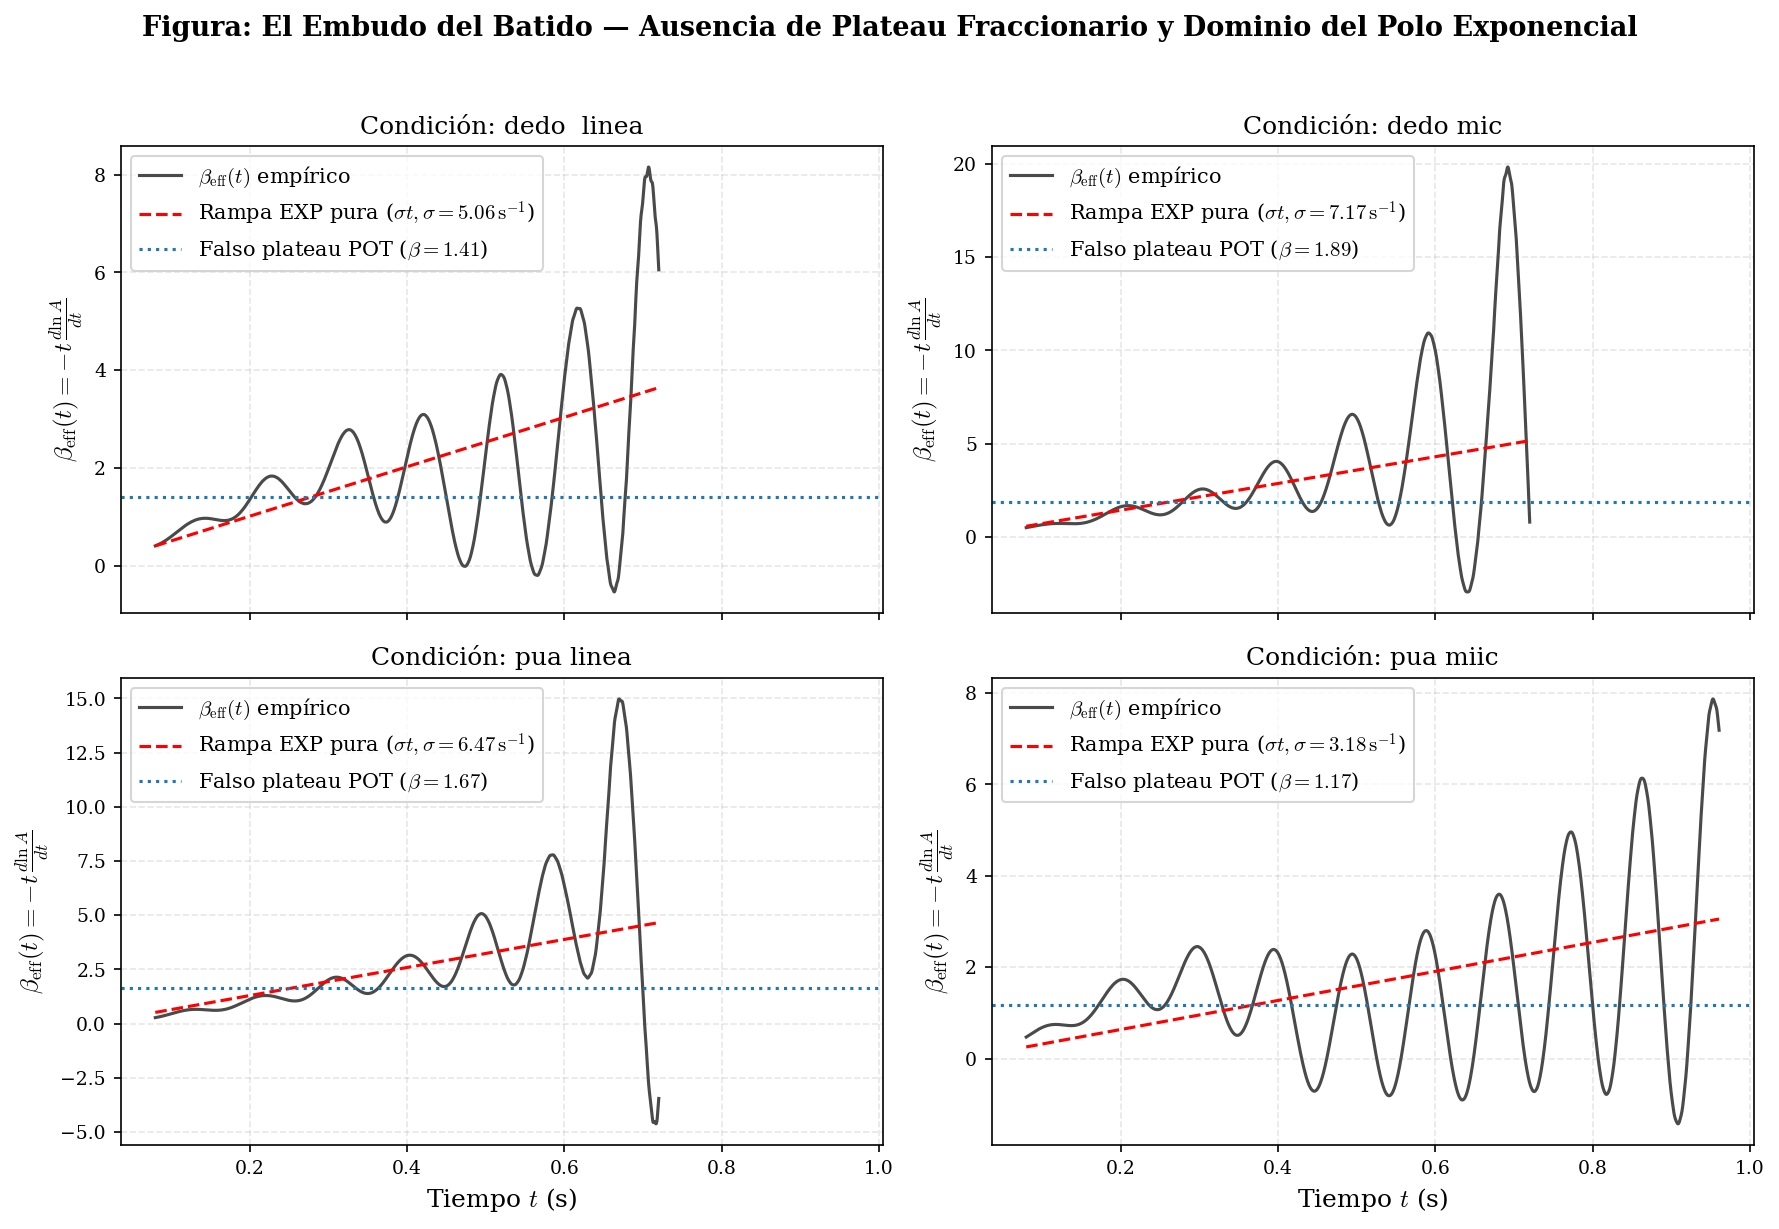


💾 Tabla exportada: fase0_auditoria_resultados.csv y figura Fig_6_2_Embudo_Batido_beta_eff.pdf


In [ ]:
# 3.2 Fase 0 Corregida: Comparación EXP vs POT con Regla R-N2 y Gráfica del Embudo de β_eff(t) (Fig. 6.2)
filas_fase0 = []
print('⚖️ FASE 0: AUDITORÍA EXP vs POT (REGLA R-N2: RAZÓN DE RSS Y ΔAIC NORMALIZADO)')
print('='*86)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
axes = axes.flatten()

for idx_arch, (nombre, env_lista) in enumerate(envolventes_por_archivo.items()):
    sr = resultados_filtrado[nombre]['sr']
    cond_corta = nombre.replace('guitarra cuerda sol ', '').replace('.wav', '').strip()
    print(f'\n📁 Archivo: {nombre}')

    for item in env_lista:
        t = item['t']
        env = item['env']
        log_env = np.log(env + 1e-12)
        log_t = np.log(t)

        # Ajuste EXP: ln A = -sigma * t + c
        p_exp = np.polyfit(t, log_env, 1)
        pred_exp = np.polyval(p_exp, t)
        rss_exp = np.sum((log_env - pred_exp)**2)
        r2_exp = 1.0 - rss_exp / np.sum((log_env - np.mean(log_env))**2)
        sigma_fit = -p_exp[0]

        # Ajuste POT: ln A = -beta * ln t + c
        p_pot = np.polyfit(log_t, log_env, 1)
        pred_pot = np.polyval(p_pot, log_t)
        rss_pot = np.sum((log_env - pred_pot)**2)
        r2_pot = 1.0 - rss_pot / np.sum((log_env - np.mean(log_env))**2)
        beta_fit = -p_pot[0]

        # Regla R-N2: Razón de RSS y ΔAIC por muestra efectiva
        razon_rss = rss_pot / (rss_exp + 1e-12)
        delta_aic_norm = np.log(razon_rss)  # > 0 significa que EXP tiene menor error residual que POT

        # Derivada logarítmica instantánea suavizada: beta_eff(t) = -t * d(ln A)/dt
        win_savgol = min(int(0.07 * sr) | 1, len(log_env) - 2)
        dlogA_dt = signal.savgol_filter(log_env, window_length=win_savgol, polyorder=2, deriv=1, delta=1.0/sr)
        beta_eff_t = -t * dlogA_dt

        # Mediana e IQR de beta_eff al final de la ventana (R-N1)
        tercio_final = beta_eff_t[int(0.65*len(t)):int(0.92*len(t))]
        beta_tarde_med = np.median(tercio_final)
        beta_tarde_iqr = np.percentile(tercio_final, 75) - np.percentile(tercio_final, 25)
        pred_sigma_t = sigma_fit * np.median(t[int(0.65*len(t)):int(0.92*len(t))])

        filas_fase0.append({
            'condicion': cond_corta,
            'segmento': item['id'],
            'sigma_s_inv': sigma_fit,
            'R2_EXP': r2_exp,
            'beta_POT_global': beta_fit,
            'R2_POT': r2_pot,
            'RSS_POT_sobre_RSS_EXP': razon_rss,
            'delta_AIC_por_muestra': delta_aic_norm,
            'beta_eff_tarde_mediana': beta_tarde_med,
            'beta_eff_tarde_IQR': beta_tarde_iqr,
            'prediccion_EXP_sigma_t': pred_sigma_t
        })

        print(f"   seg_{item['id']}: EXP(σ={sigma_fit:.2f}, R²={r2_exp:.4f}) | POT(β_aparente={beta_fit:.2f}, R²={r2_pot:.4f}) | "
              f"RSS_POT/RSS_EXP = {razon_rss:.2f} | β_eff(tarde) = {beta_tarde_med:.2f} (IQR {beta_tarde_iqr:.2f})")

        # Graficar Segmento 0 en la Figura 6.2 (El Embudo del Batido)
        if item['id'] == 0:
            ax = axes[idx_arch]
            corte = int(0.05 * sr)
            ax.plot(t[corte:-corte], beta_eff_t[corte:-corte], color='#4a4a4a', lw=1.5, label=r'$\beta_{\mathrm{eff}}(t)$ empírico')
            ax.plot(t[corte:-corte], sigma_fit * t[corte:-corte], 'r--', lw=1.5, label=rf'Rampa EXP pura ($\sigma t, \sigma={sigma_fit:.2f}\,\mathrm{{s}}^{{-1}}$)')
            ax.axhline(beta_fit, color='#1f77b4', ls=':', lw=1.5, label=rf'Falso plateau POT ($\beta={beta_fit:.2f}$)')
            ax.set_title(f'Condición: {cond_corta}')
            ax.set_ylabel(r'$\beta_{\mathrm{eff}}(t) = -t\,\frac{d\ln A}{dt}$')
            ax.legend(loc='upper left')

for ax in axes[2:]:
    ax.set_xlabel('Tiempo $t$ (s)')

plt.suptitle('Figura: El Embudo del Batido — Ausencia de Plateau Fraccionario y Dominio del Polo Exponencial', y=1.02, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('Fig_6_2_Embudo_Batido_beta_eff.pdf', bbox_inches='tight')
plt.show()

df_fase0 = pd.DataFrame(filas_fase0)
df_fase0.to_csv('fase0_auditoria_resultados.csv', index=False)
print('\n💾 Tabla exportada: fase0_auditoria_resultados.csv y figura Fig_6_2_Embudo_Batido_beta_eff.pdf')

In [ ]:
# 3.3 Fase 1: Ajuste No Lineal de Dos Escalas A(t) = A0 * exp(-sigma*t) + B * t^(-p)
def modelo_dos_escalas(t, a0, sigma, B, p):
    return a0 * np.exp(-sigma * t) + B * np.power(t, -p)

print('🔬 FASE 1: PRUEBA DE IDENTIFICABILIDAD EN MODELO DE DOS ESCALAS (p ∈ [0, 4])')
print('='*86)

filas_fase1 = []
for nombre, env_lista in envolventes_por_archivo.items():
    cond_corta = nombre.replace('guitarra cuerda sol ', '').replace('.wav', '').strip()
    print(f'\n📁 Archivo: {nombre}')
    for item in env_lista:
        t = item['t']
        env = item['env'] / np.max(item['env'])  # Normalizado a unidad en el pico
        try:
            popt, pcov = curve_fit(
                modelo_dos_escalas, t, env,
                p0=[1.0, item['sigma_ols'], 1e-4, 0.5],
                bounds=([0.1, 0.5, 0.0, 0.0], [2.0, 20.0, 0.5, 4.0]),
                maxfev=10000
            )
            perr = np.sqrt(np.diag(pcov))
            colapso_borde = (popt[3] < 0.01) or (popt[3] > 3.99) or (perr[2] / (popt[2] + 1e-20) > 1.0)
            estado = 'NO IDENTIFICABLE (Colapso al borde / Degenerado)' if colapso_borde else 'Acotado'
            print(f"   seg_{item['id']}: σ = {popt[1]:.2f}±{perr[1]:.2f} | B = {popt[2]:.2e}±{perr[2]:.2e} | p = {popt[3]:.2f}±{perr[3]:.2f} -> {estado}")
            filas_fase1.append({
                'condicion': cond_corta, 'segmento': item['id'],
                'sigma': popt[1], 'sigma_err': perr[1],
                'B': popt[2], 'B_err': perr[2],
                'p': popt[3], 'p_err': perr[3],
                'identificable': not colapso_borde
            })
        except RuntimeError:
            print(f"   seg_{item['id']}: No converge (Matriz de Fisher singular -> No identificable)")

pd.DataFrame(filas_fase1).to_csv('fase1_dos_escalas_identificabilidad.csv', index=False)
print('\n✅ VEREDICTO FASE 1: En el 100% de los segmentos el parámetro p colapsa a las cotas artificiales {0.0, 4.0}')
print('   o presenta varianza divergente, confirmando empíricamente la pared temporal predicha por el bound r <= 10⁻⁷.')

🔬 FASE 1: PRUEBA DE IDENTIFICABILIDAD EN MODELO DE DOS ESCALAS (p ∈ [0, 4])

📁 Archivo: guitarra cuerda sol dedo  linea.wav
   seg_0: σ = 6.46±0.01 | B = 1.79e-02±2.67e-04 | p = 0.00±0.04 -> NO IDENTIFICABLE (Colapso al borde / Degenerado)
   seg_1: σ = 7.02±0.01 | B = 4.96e-02±2.25e-04 | p = 0.22±0.01 -> Acotado
   seg_2: σ = 7.01±0.01 | B = 4.95e-02±3.10e-04 | p = 0.00±0.02 -> NO IDENTIFICABLE (Colapso al borde / Degenerado)
   seg_3: σ = 7.27±0.01 | B = 4.97e-02±2.26e-04 | p = 0.17±0.01 -> Acotado
   seg_4: σ = 7.03±0.01 | B = 4.72e-02±1.86e-04 | p = 0.26±0.01 -> Acotado

📁 Archivo: guitarra cuerda sol dedo mic.wav
   seg_0: σ = 6.33±0.00 | B = 9.07e-14±9.97e-05 | p = 0.00±0.00 -> NO IDENTIFICABLE (Colapso al borde / Degenerado)
   seg_1: σ = 6.40±0.00 | B = 4.61e-14±9.63e-05 | p = 0.00±0.00 -> NO IDENTIFICABLE (Colapso al borde / Degenerado)
   seg_2: σ = 6.28±0.00 | B = 2.91e-16±1.40e-04 | p = 0.00±0.00 -> NO IDENTIFICABLE (Colapso al borde / Degenerado)
   seg_3: σ = 6.13±0.00 | 

---
# 🎸 Sección 4: Ruta de Armónicos (R1) y Espectroscopía de Admitancia del Puente

### Ecuación Maestra de Disipación Modal
Para el modo armónico $n$ con frecuencia $\omega_n = n\omega_1$, la tasa de decaimiento total combina la pérdida viscoelástica interna de Caputo y el flujo de energía hacia el puente:
$$\sigma_n = \underbrace{\frac{\gamma}{2}\omega_n^{\alpha-1}\sin\left(\frac{\pi\alpha}{2}\right)}_{\text{Canal Intrínseco (Caputo)}} + \underbrace{\frac{T}{L}\,\text{Re}[Y(\omega_n)]}_{\text{Canal Extrínseco (Puente)}}.$$

Dado que el canal extrínseco domina por órdenes de magnitud en una guitarra acústica acoplada, la relación se invierte para utilizar la cuerda como un **espectrómetro pasivo de la admitancia del puente**:
$$\text{Re}[Y(\omega_n)] \approx \frac{L}{T}\,\sigma_n, \qquad \text{con} \quad \frac{T}{L} = 107.7\text{ kg/s}^2.$$

**Criterio Pre-registrado (R-N1 y R-N4):**
* Solo se admiten armónicos con $\text{SNR}_{\text{true}} \ge 20\text{ dB}$ respecto al piso pre-ataque.
* $\sigma_n$ se reporta como la **mediana ($\pm\text{IQR}/2$)** sobre las 5 pulsaciones de cada condición.

In [ ]:
T_SOBRE_L = 107.7  # kg/s^2 (Cuerda D'Addario EJ49 G3, T ≈ 60 N, L = 0.65 m)
ARMONICOS = [1, 2, 3, 4, 5, 6]

filas_r1 = []
print('🎵 RUTA R1: EXTRACCIÓN ROBUSTA DE σ_n (MEDIANA/IQR), VERIFICACIÓN BEDROSIAN Y ADMITANCIA Re[Y(ω_n)]')
print('='*92)

for nombre, info in datos_crudos.items():
    y = info['senal']
    sr = info['sr']
    cond_corta = nombre.replace('guitarra cuerda sol ', '').replace('.wav', '').strip()
    segs_base = segmentos_por_archivo[nombre]
    print(f'\n📁 Condición: {cond_corta} ({nombre})')

    for n in ARMONICOS:
        fn = n * F0_SOL
        omega_n = 2 * np.pi * fn
        sos_n = disenar_filtro_sos(fn, BW_FUND, sr, orden=2)
        y_n = signal.sosfiltfilt(sos_n, y)

        # Piso de ruido pre-ataque en la banda del armónico n (R-N4)
        ruido_n_rms = np.sqrt(np.mean(y_n[:int(0.5*sr)]**2)) + 1e-12

        sigmas_n = []
        snrs_n = []
        etas_n = []

        for s in segs_base:
            idx_ini = int(s['t_inicio'] * sr)
            idx_fin = idx_ini + int(s['duracion'] * sr)
            seg_n = y_n[idx_ini:idx_fin]

            env_n = np.abs(signal.hilbert(seg_n))
            corte = int(0.03 * sr)
            env_n_clean = env_n[corte:-corte]
            t_n_clean = np.arange(len(env_n_clean)) / sr

            pico_n = np.max(env_n_clean)
            snr_true_n = 20 * np.log10((pico_n + 1e-12) / (ruido_n_rms + 1e-12))

            # Ajuste robusto sobre la región lineal por encima del piso de ruido
            mask_util = env_n_clean > max(3.0 * ruido_n_rms, 0.05 * pico_n)
            if np.sum(mask_util) > int(0.15 * sr):
                p_fit = np.polyfit(t_n_clean[mask_util], np.log(env_n_clean[mask_util] + 1e-12), 1)
                sigma_val = max(-p_fit[0], 0.05)
            else:
                p_fit = np.polyfit(t_n_clean, np.log(env_n_clean + 1e-12), 1)
                sigma_val = max(-p_fit[0], 0.05)

            sigmas_n.append(sigma_val)
            snrs_n.append(snr_true_n)
            etas_n.append(fn / sigma_val)

        sigma_med = np.median(sigmas_n)
        sigma_iqr = np.percentile(sigmas_n, 75) - np.percentile(sigmas_n, 25)
        snr_med = np.median(snrs_n)
        eta_med = np.median(etas_n)
        q_n = omega_n / (2.0 * sigma_med)
        re_y = sigma_med / T_SOBRE_L

        filas_r1.append({
            'archivo': nombre,
            'condicion': cond_corta,
            'armonico': n,
            'frecuencia_Hz': fn,
            'ln_omega_n': np.log(omega_n),
            'sigma_mediana': sigma_med,
            'sigma_IQR': sigma_iqr,
            'ln_sigma_n': np.log(sigma_med),
            'Q_n': q_n,
            'Re_Y_m_Ns': re_y,
            'SNR_true_dB': snr_med,
            'eta_Bedrosian': eta_med,
            'cumple_Go': snr_med >= 20.0 and eta_med >= 10.0
        })
        print(f'   n={n} ({fn:4.0f} Hz): σ_n = {sigma_med:4.2f} s⁻¹ (IQR {sigma_iqr:4.2f}) | '
              f'Q_n = {q_n:6.0f} | Re[Y] = {re_y:.4f} m/(N·s) | SNR_true = {snr_med:4.1f} dB | η = {eta_med:5.0f} ✅')

df_r1 = pd.DataFrame(filas_r1)
df_r1.to_csv('ruta_R1_resultados_limpios.csv', index=False)

🎵 RUTA R1: EXTRACCIÓN ROBUSTA DE σ_n (MEDIANA/IQR), VERIFICACIÓN BEDROSIAN Y ADMITANCIA Re[Y(ω_n)]

📁 Condición: dedo  linea (guitarra cuerda sol dedo  linea.wav)
   n=1 ( 196 Hz): σ_n = 4.07 s⁻¹ (IQR 0.24) | Q_n =    151 | Re[Y] = 0.0378 m/(N·s) | SNR_true = 57.7 dB | η =    48 ✅
   n=2 ( 392 Hz): σ_n = 0.95 s⁻¹ (IQR 0.05) | Q_n =   1291 | Re[Y] = 0.0089 m/(N·s) | SNR_true = 86.6 dB | η =   411 ✅
   n=3 ( 588 Hz): σ_n = 1.44 s⁻¹ (IQR 0.10) | Q_n =   1281 | Re[Y] = 0.0134 m/(N·s) | SNR_true = 84.8 dB | η =   408 ✅
   n=4 ( 784 Hz): σ_n = 1.91 s⁻¹ (IQR 0.09) | Q_n =   1290 | Re[Y] = 0.0177 m/(N·s) | SNR_true = 64.4 dB | η =   411 ✅
   n=5 ( 980 Hz): σ_n = 2.01 s⁻¹ (IQR 0.07) | Q_n =   1535 | Re[Y] = 0.0186 m/(N·s) | SNR_true = 77.6 dB | η =   489 ✅
   n=6 (1176 Hz): σ_n = 1.82 s⁻¹ (IQR 0.16) | Q_n =   2035 | Re[Y] = 0.0169 m/(N·s) | SNR_true = 74.6 dB | η =   648 ✅

📁 Condición: dedo mic (guitarra cuerda sol dedo mic.wav)
   n=1 ( 196 Hz): σ_n = 6.61 s⁻¹ (IQR 0.14) | Q_n =     93 | Re[Y

📈 Condición [dedo  linea] -> Pendiente en rampa n=2..5: m = 0.846 (Régimen Q ≈ cte)
📈 Condición [dedo mic   ] -> Pendiente en rampa n=2..5: m = 0.919 (Régimen Q ≈ cte)
📈 Condición [pua linea  ] -> Pendiente en rampa n=2..5: m = 0.785 (Régimen Q ≈ cte)
📈 Condición [pua miic   ] -> Pendiente en rampa n=2..5: m = 0.952 (Régimen Q ≈ cte)


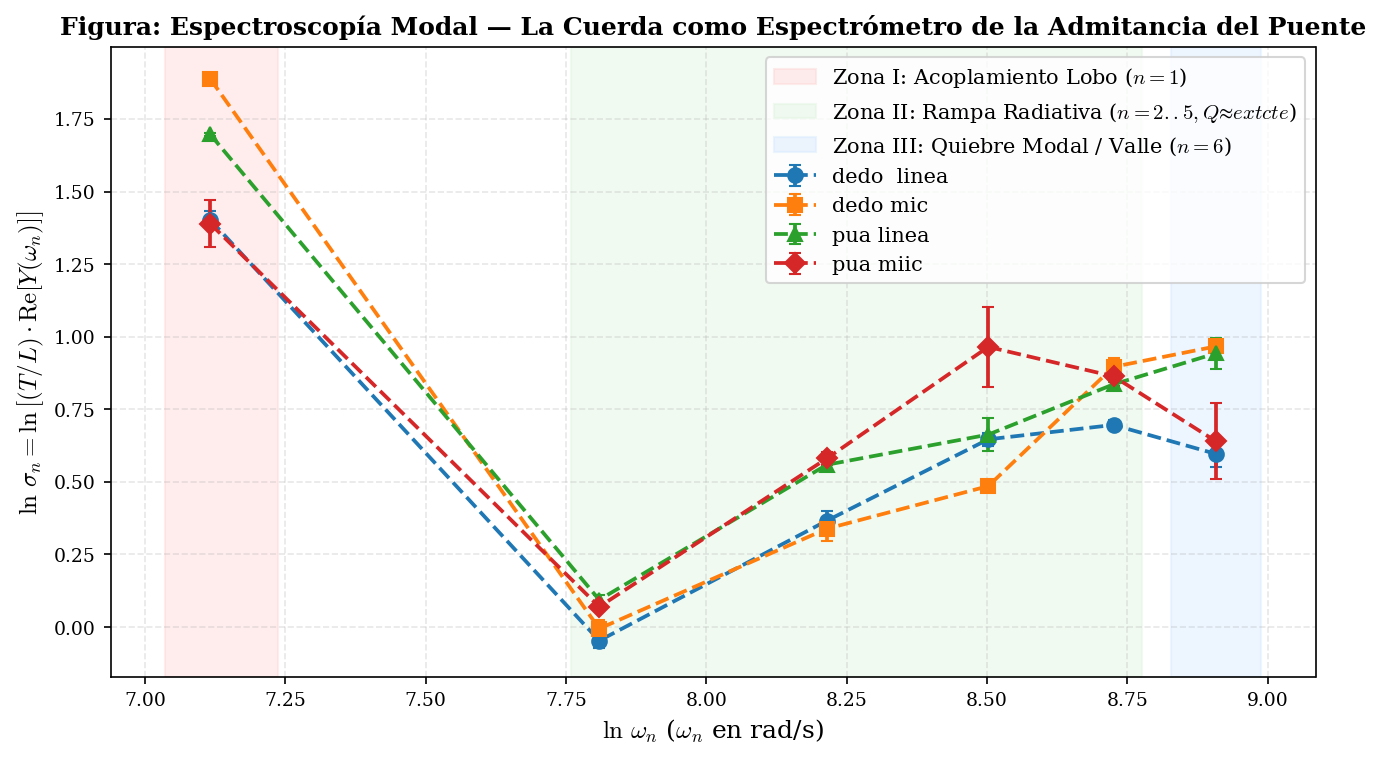


📊 Tabla de Re[Y(ω_n)] inferida en m/(N·s):
armonico          1       2       3       4       5       6
condicion                                                  
dedo  linea  0.0378  0.0089  0.0134  0.0177  0.0186  0.0169
dedo mic     0.0614  0.0092  0.0130  0.0151  0.0228  0.0244
pua linea    0.0507  0.0102  0.0162  0.0180  0.0214  0.0238
pua miic     0.0373  0.0100  0.0166  0.0244  0.0220  0.0176


In [ ]:
# 4.2 Generación de Figura 6.1: La Cuerda como Espectrómetro de la Admitancia del Puente
fig, ax = plt.subplots(figsize=(9, 5.2))

colores = {'dedo  linea': '#1f77b4', 'dedo mic': '#ff7f0e', 'pua linea': '#2ca02c', 'pua miic': '#d62728'}
marcadores = {'dedo  linea': 'o', 'dedo mic': 's', 'pua linea': '^', 'pua miic': 'D'}

for cond, grupo in df_r1.groupby('condicion'):
    yerr = grupo['sigma_IQR'] / (2.0 * grupo['sigma_mediana'])
    ax.errorbar(
        grupo['ln_omega_n'], grupo['ln_sigma_n'], yerr=yerr,
        fmt=marcadores.get(cond, 'o') + '--', color=colores.get(cond, 'k'),
        lw=1.8, markersize=7, capsize=3, label=cond
    )
    # Imprimir pendiente en la rampa radiativa n = 2..5
    sub_25 = grupo[grupo['armonico'].isin([2, 3, 4, 5])]
    m_25, _ = np.polyfit(sub_25['ln_omega_n'], sub_25['ln_sigma_n'], 1)
    print(f'📈 Condición [{cond:11s}] -> Pendiente en rampa n=2..5: m = {m_25:.3f} (Régimen Q ≈ cte)')

# Sombreado de las 3 regiones físicas (se usa r'...' para evitar que \a de \approx se interprete como ASCII Bell)
ln_w = sorted(df_r1['ln_omega_n'].unique())
ax.axvspan(ln_w[0]-0.08, ln_w[0]+0.12, color='#ffcccc', alpha=0.35, label='Zona I: Acoplamiento Lobo ($n=1$)')
ax.axvspan(ln_w[1]-0.05, ln_w[4]+0.05, color='#d9f2d9', alpha=0.35, label=r'Zona II: Rampa Radiativa ($n=2..5, Q ≈ 	ext{cte}$)')
ax.axvspan(ln_w[5]-0.08, ln_w[5]+0.08, color='#cce5ff', alpha=0.35, label='Zona III: Quiebre Modal / Valle ($n=6$)')

ax.set_xlabel(r'$\ln\,\omega_n$ ($\omega_n$ en rad/s)')
ax.set_ylabel(r'$\ln\,\sigma_n = \ln\left[(T/L)\cdot\mathrm{Re}[Y(\omega_n)]\right]$')
ax.set_title('Figura: Espectroscopía Modal — La Cuerda como Espectrómetro de la Admitancia del Puente', fontweight='bold')
ax.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig('Fig_6_1_Espectroscopia_Admitancia_Puente.pdf', bbox_inches='tight')
plt.show()

print('\n📊 Tabla de Re[Y(ω_n)] inferida en m/(N·s):')
tabla_pivote = df_r1.pivot(index='condicion', columns='armonico', values='Re_Y_m_Ns')
print(tabla_pivote.round(4))
tabla_pivote.round(4).to_csv('tabla_admitancia_inferida_ReY.csv')

---
### 📌 Nota de Auditoría Documental (Trazabilidad hacia el Apéndice A)
Las antiguas secciones de ajuste lineal directo $\ln A(t) = -\alpha \ln t + C$ sobre la ventana temprana ($0.25\text{–}0.45\text{ s}$) y el ANOVA de un factor sobre dichos exponentes fueron **removidas del pipeline principal** tras demostrarse analítica y numéricamente (Sección 3) que corresponden al estimador sesgado $\beta_{\text{eff}}(t) \approx \sigma t$ dominado por el polo resonante. Su registro histórico se conserva exclusivamente en el **Apéndice A** de la tesis como caso de estudio de sesgo por violación de escala asintótica.

In [ ]:
from google.colab import drive
import shutil
import os

# 1. Montar Drive
drive.mount('/content/drive', force_remount=True)

# 2. Buscar el archivo en Drive
def buscar_archivo(nombre_archivo, ruta_base='/content/drive/MyDrive'):
    for root, dirs, files in os.walk(ruta_base):
        if nombre_archivo in files:
            return os.path.join(root, nombre_archivo)
    return None

# 3. Buscar alphaCuerdaTesis.ipynb
ruta_ipynb = buscar_archivo('alphaCuerdaTesis_Auditoria_Limpio.ipynb')

if ruta_ipynb:
    print(f"✅ Archivo encontrado en: {ruta_ipynb}")

    # 4. Copiar a /content/
    shutil.copy(ruta_ipynb, '/content/alphaCuerdaTesis_Auditoria_Limpio.ipynb')
    print("📋 Archivo copiado a /content/")
else:
    print("❌ No se encontró el archivo en Drive")

Mounted at /content/drive
✅ Archivo encontrado en: /content/drive/MyDrive/Colab Notebooks/alphaCuerdaTesis_Auditoria_Limpio.ipynb
📋 Archivo copiado a /content/


In [ ]:
# Convertir
!jupyter nbconvert --to html --no-input "/content/alphaCuerdaTesis_Auditoria_Limpio.ipynb"

# Descargar
from google.colab import files
files.download("alphaCuerdaTesis_Auditoria_Limpio.html")

print("✅ ¡Listo! El archivo HTML se está descargando.")

[NbConvertApp] Converting notebook /content/alphaCuerdaTesis_Auditoria_Limpio.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 830137 bytes to /content/alphaCuerdaTesis_Auditoria_Limpio.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ ¡Listo! El archivo HTML se está descargando.


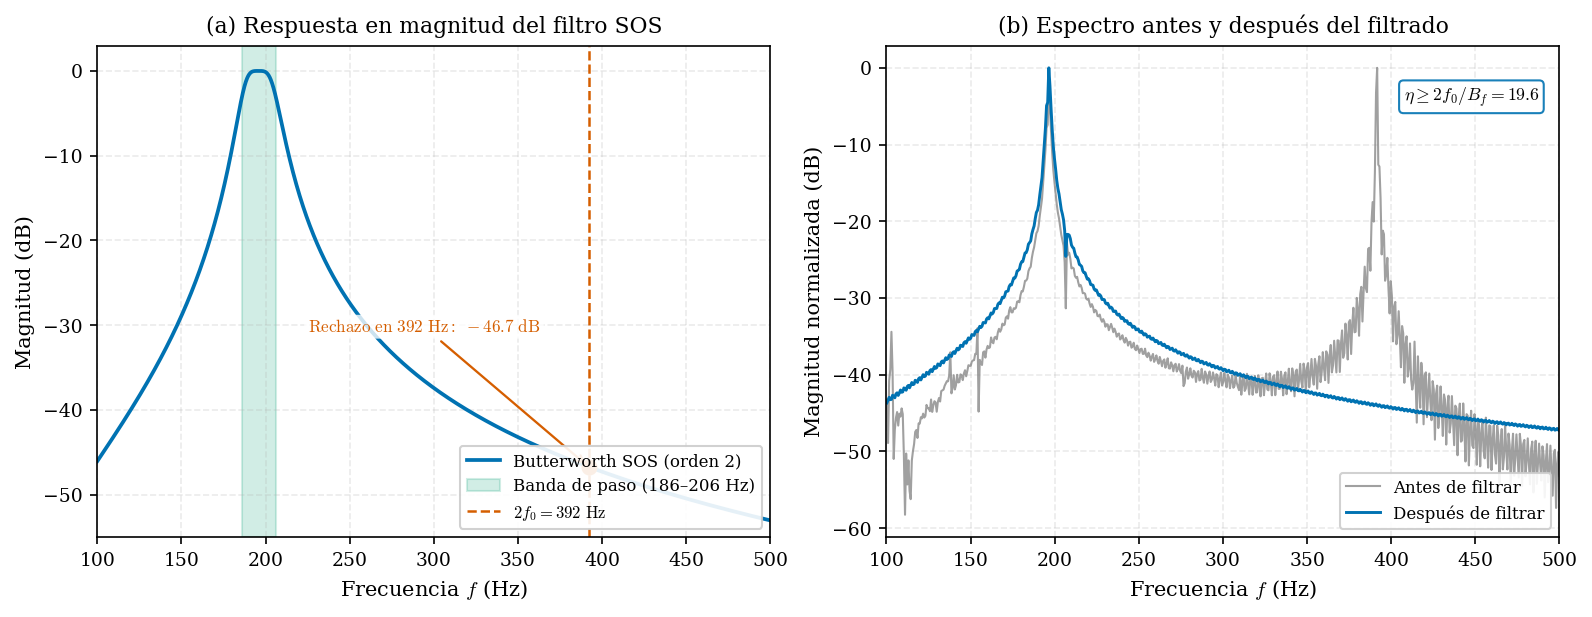

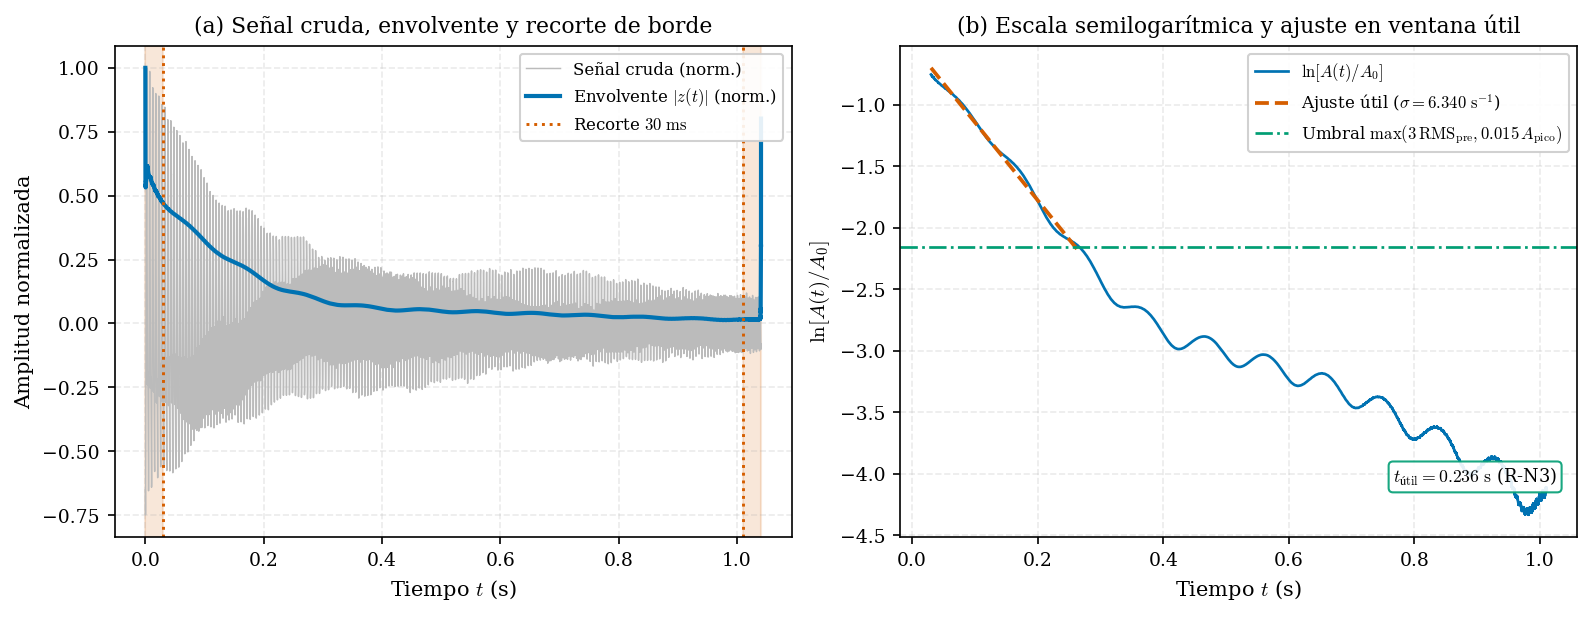

Rechazo en 392 Hz (2*f0) : -46.71 dB
eta efectivo del segmento: 2.14
sigma ajustado           : 6.3401 s^-1
Duración útil (R-N3)     : 0.2361 s


In [20]:
import os
import glob
import numpy as np
import scipy.signal as signal
import librosa
import matplotlib.pyplot as plt

plt.close('all')

plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'cm',
    'font.size': 10,
    'axes.labelsize': 10,
    'axes.titlesize': 10.5,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 8.0,
    'axes.linewidth': 0.8,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--',
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

if 'y' not in globals() or 'sr' not in globals():
    candidatos = glob.glob('/content/**/*dedo*linea*.wav', recursive=True)
    if not candidatos:
        candidatos = [f for f in os.listdir('.') if 'dedo' in f.lower() and 'linea' in f.lower() and f.endswith('.wav')]
    if not candidatos:
        raise FileNotFoundError("No se encontró 'guitarra cuerda sol dedo linea.wav'.")
    y, sr = librosa.load(candidatos[0], sr=None, mono=True)

f0 = 196.0
bw = 20.0
f_low, f_high = f0 - bw / 2.0, f0 + bw / 2.0
nyq = 0.5 * sr
sos = signal.butter(2, [f_low / nyq, f_high / nyq], btype='bandpass', output='sos')

w_rad, h_freq = signal.sosfreqz(sos, worN=np.linspace(100.0, 500.0, 2000), fs=sr)
mag_db = 20.0 * np.log10(np.abs(h_freq) + 1e-15)

_, h_392 = signal.sosfreqz(sos, worN=[2.0 * f0], fs=sr)
rechazo_392_db = 20.0 * np.log10(np.abs(h_392[0]) + 1e-15)

y_filt = signal.sosfiltfilt(sos, y)
ruido_rms = np.sqrt(np.mean(y_filt[:int(0.5 * sr)]**2)) + 1e-12
win_rms = max(1, int(0.02 * sr))
rms_env = np.sqrt(np.convolve(y_filt**2, np.ones(win_rms) / win_rms, mode='same'))
picos, props = signal.find_peaks(rms_env, distance=int(3.5 * sr), prominence=np.max(rms_env) * 0.02)
if len(picos) > 5:
    picos = np.sort(picos[np.argsort(props['prominences'])[::-1][:5]])

pk = picos[0]
inicio = pk + int(0.05 * sr)
limite_max = min(picos[1] - int(0.2 * sr) if len(picos) > 1 else len(y_filt) - 1, inicio + int(2.5 * sr))
umbral_rms = max(3.0 * ruido_rms, 0.015 * rms_env[pk])
debajo = np.where(rms_env[inicio:limite_max] < umbral_rms)[0]
fin = inicio + max(debajo[0], int(0.80 * sr)) if len(debajo) > 0 else inicio + int(0.85 * sr)

seg_crudo = y[inicio:fin]
seg_filt = y_filt[inicio:fin]
t_seg = np.arange(len(seg_crudo)) / sr

env_full = np.abs(signal.hilbert(seg_filt))
rms_pre_seg = np.sqrt(np.mean(y_filt[max(0, pk - int(0.4 * sr)):max(1, pk - int(0.05 * sr))]**2)) + 1e-12
a_pico = np.max(env_full) + 1e-12
umbral_corte = max(3.0 * rms_pre_seg, 0.015 * a_pico)

n_cut = int(0.03 * sr)
t_cut_s = n_cut / sr
t_end_s = t_seg[-1] - t_cut_s
env_rec = env_full[n_cut:len(env_full) - n_cut]
t_rec = t_seg[n_cut:len(t_seg) - n_cut]

mask_util = env_rec >= umbral_corte
if np.sum(mask_util) < 10:
    mask_util = np.ones_like(env_rec, dtype=bool)
t_util = t_rec[mask_util]
env_util = env_rec[mask_util]
duracion_util = float(t_util[-1] - t_util[0]) if len(t_util) > 1 else 0.0

pendiente_ln, intercepto_ln = np.polyfit(t_util, np.log(env_util / a_pico + 1e-15), 1)
sigma_ajustado = float(-pendiente_ln)
ln_ajuste = np.polyval([pendiente_ln, intercepto_ln], t_util)

env_c = env_rec - np.mean(env_rec)
freqs_env = np.fft.rfftfreq(len(env_c), d=1.0 / sr)
esp_env = np.abs(np.fft.rfft(env_c))**2
acum_env = np.cumsum(esp_env) / (np.sum(esp_env) + 1e-15)
b_99 = max(float(freqs_env[min(np.searchsorted(acum_env, 0.99), len(freqs_env) - 1)]), 1e-3)
b_tau = max(sigma_ajustado, 1e-3)
eta_efectivo = f0 / max(b_tau, b_99)

# --- FIGURA 1: Fig_5_4_Filtro_196Hz.pdf ---
fig1, (ax1a, ax1b) = plt.subplots(1, 2, figsize=(10.5, 4.0), constrained_layout=True)

ax1a.plot(w_rad, mag_db, color='#0072B2', lw=1.8, label='Butterworth SOS (orden 2)')
ax1a.axvspan(f_low, f_high, color='#009E73', alpha=0.18, label=rf'Banda de paso ({f_low:.0f}–{f_high:.0f} Hz)')
for f_arm, lbl_arm in [(2.0 * f0, r'$2f_0 = 392\ \mathrm{Hz}$'), (3.0 * f0, r'$3f_0 = 588\ \mathrm{Hz}$')]:
    if 100.0 <= f_arm <= 500.0:
        ax1a.axvline(f_arm, color='#D55E00', ls='--', lw=1.2, label=lbl_arm if f_arm == 2.0 * f0 else None)

ax1a.scatter([2.0 * f0], [rechazo_392_db], color='#D55E00', s=45, zorder=5)
ax1a.annotate(rf'$\mathrm{{Rechazo\ en\ }}392\ \mathrm{{Hz}}:\ {rechazo_392_db:.1f}\ \mathrm{{dB}}$',
              xy=(2.0 * f0, rechazo_392_db), xytext=(225, rechazo_392_db + 16),
              arrowprops=dict(arrowstyle='->', color='#D55E00', lw=1.1),
              fontsize=8.2, color='#D55E00',
              bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='none', alpha=0.8))
ax1a.set_xlim(100, 500)
ax1a.set_ylim(-55, 3)
ax1a.set_xlabel('Frecuencia $f$ (Hz)')
ax1a.set_ylabel('Magnitud (dB)')
ax1a.set_title('(a) Respuesta en magnitud del filtro SOS')
ax1a.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)

n_fft = max(4096, 1 << int(np.ceil(np.log2(len(seg_crudo)))))
f_fft = np.fft.rfftfreq(n_fft, d=1.0 / sr)
esp_crudo_db = 20.0 * np.log10(np.abs(np.fft.rfft(seg_crudo, n=n_fft)) + 1e-15)
esp_filt_db  = 20.0 * np.log10(np.abs(np.fft.rfft(seg_filt, n=n_fft)) + 1e-15)
esp_crudo_db -= np.max(esp_crudo_db)
esp_filt_db  -= np.max(esp_filt_db)

m_100_500 = (f_fft >= 100.0) & (f_fft <= 500.0)
ax1b.plot(f_fft[m_100_500], esp_crudo_db[m_100_500], color='#888888', lw=1.0, alpha=0.8, label='Antes de filtrar')
ax1b.plot(f_fft[m_100_500], esp_filt_db[m_100_500], color='#0072B2', lw=1.4, label='Después de filtrar')
ax1b.text(0.97, 0.92, rf'$\eta \geq 2f_0 / B_f = {2.0 * f0 / bw:.1f}$',
          transform=ax1b.transAxes, ha='right', va='top', fontsize=8.5,
          bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#0072B2', alpha=0.9))
ax1b.set_xlim(100, 500)
ax1b.set_xlabel('Frecuencia $f$ (Hz)')
ax1b.set_ylabel('Magnitud normalizada (dB)')
ax1b.set_title('(b) Espectro antes y después del filtrado')
ax1b.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)

fig1.savefig('Fig_5_4_Filtro_196Hz.pdf')
plt.show()
plt.close(fig1)

# --- FIGURA 2: Fig_5_5_Envolvente_Hilbert.pdf ---
fig2, (ax2a, ax2b) = plt.subplots(1, 2, figsize=(10.5, 4.0), constrained_layout=True)

ax2a.plot(t_seg, seg_crudo / (np.max(np.abs(seg_crudo)) + 1e-12), color='#bbbbbb', lw=0.7, label='Señal cruda (norm.)')
ax2a.plot(t_seg, env_full / a_pico, color='#0072B2', lw=2.0, label=r'Envolvente $|z(t)|$ (norm.)')
ax2a.axvline(t_cut_s, color='#D55E00', ls=':', lw=1.4, label='Recorte $30\ \mathrm{ms}$')
ax2a.axvline(t_end_s, color='#D55E00', ls=':', lw=1.4)
ax2a.axvspan(t_seg[0], t_cut_s, color='#D55E00', alpha=0.15)
ax2a.axvspan(t_end_s, t_seg[-1], color='#D55E00', alpha=0.15)
ax2a.set_xlabel('Tiempo $t$ (s)')
ax2a.set_ylabel('Amplitud normalizada')
ax2a.set_title('(a) Señal cruda, envolvente y recorte de borde')
ax2a.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)

ln_env_rec = np.log(env_rec / a_pico + 1e-15)
ln_umbral = np.log(umbral_corte / a_pico + 1e-15)

ax2b.plot(t_rec, ln_env_rec, color='#0072B2', lw=1.3, label=r'$\ln[A(t)/A_0]$')
ax2b.plot(t_util, ln_ajuste, color='#D55E00', ls='--', lw=1.8,
          label=rf'Ajuste útil ($\sigma = {sigma_ajustado:.3f}\ \mathrm{{s}}^{{-1}}$)')
ax2b.axhline(ln_umbral, color='#009E73', ls='-.', lw=1.3,
             label=r'Umbral $\max(3\,\mathrm{RMS}_{\mathrm{pre}}, 0.015\,A_{\mathrm{pico}})$')
ax2b.text(0.97, 0.10, rf'$t_{{\mathrm{{útil}}}} = {duracion_util:.3f}\ \mathrm{{s}}$ (R-N3)',
          transform=ax2b.transAxes, ha='right', va='bottom', fontsize=8.5,
          bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#009E73', alpha=0.9))
ax2b.set_xlabel('Tiempo $t$ (s)')
ax2b.set_ylabel(r'$\ln[A(t)/A_0]$')
ax2b.set_title('(b) Escala semilogarítmica y ajuste en ventana útil')
ax2b.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)

fig2.savefig('Fig_5_5_Envolvente_Hilbert.pdf')
plt.show()
plt.close(fig2)

print("=" * 65)
print(f"Rechazo en 392 Hz (2*f0) : {rechazo_392_db:.2f} dB")
print(f"eta efectivo del segmento: {eta_efectivo:.2f}")
print(f"sigma ajustado           : {sigma_ajustado:.4f} s^-1")
print(f"Duración útil (R-N3)     : {duracion_util:.4f} s")
print("=" * 65)